# 03 · Extended Feature Discovery: History, Trends, Recency & Module Patterns

**Exploratory notebook only.** This notebook constructs candidate features in memory and compares their distributions with the supplied student-level `dropped_out` target. It does **not** export modeling datasets or train models.

## Fixed prediction/target assumptions

- The target is the supplied eventual `dropped_out` label. This notebook does not redefine it.
- For students with at least 2 recorded attempts, the prediction point is the **penultimate recorded attempt**. Only the chronological prefix ending at that attempt is visible to feature construction.
- The **2–3 total-attempt cohort** receives a compact feature exploration: a 2-attempt student has one attempt in the prefix; a 3-attempt student has two.
- The **4+ total-attempt cohort** receives extensive feature discovery: at least three attempts are available in the prefix.
- Total attempt count is used only to select retrospective cohorts for analysis. It is excluded from feature candidates because it requires observing the future end of the student's history.
- Rows after the prediction point are never used in any candidate feature. The last attempt's outcome, timing, score, time, module, or gap is not a predictor.

Because the cohort itself is retrospective (defined by eventual total attempts), observed feature/target associations are **descriptive**, not an unbiased estimate of live deployment performance. In a real deployment, cohort eligibility must be determined from information available at that moment.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
RANDOM_STATE = 42

DATA_DIR = Path("../data")
if not (DATA_DIR / "students.csv").exists():
    DATA_DIR = Path("data")
students = pd.read_csv(DATA_DIR / "students.csv")
attempts_raw = pd.read_csv(DATA_DIR / "quiz_attempts.csv")
outcomes = pd.read_csv(DATA_DIR / "outcome.csv")

students["signup_date"] = pd.to_datetime(students.get("signup_date"), errors="coerce")
attempts = attempts_raw.copy()
attempts["attempted_at"] = pd.to_datetime(attempts["attempted_at"], errors="coerce")
attempts["score_raw"] = pd.to_numeric(attempts["score"], errors="coerce")
# 999 is a known invalid sentinel; non-finite values are invalid too.
score_finite = pd.Series(np.isfinite(attempts["score_raw"].to_numpy(dtype=float, na_value=np.nan)), index=attempts.index)
attempts["score_valid"] = attempts["score_raw"].where(score_finite & attempts["score_raw"].ne(999))
attempts["time_raw_min"] = pd.to_numeric(attempts["time_spent_min"], errors="coerce")
time_finite = pd.Series(np.isfinite(attempts["time_raw_min"].to_numpy(dtype=float, na_value=np.nan)), index=attempts.index)
attempts["time_valid_min"] = attempts["time_raw_min"].where(time_finite & attempts["time_raw_min"].ge(0))
attempts["score_is_999"] = attempts["score_raw"].eq(999)
attempts["score_missing_or_invalid"] = attempts["score_valid"].isna()
attempts["time_missing_or_invalid"] = attempts["time_valid_min"].isna()

# A valid timestamp is required for temporal ordering. Rows with missing timestamps are retained
# in the data audit, but cannot safely be assigned to a penultimate-time snapshot.
attempts = attempts.sort_values(["student_id", "attempted_at", "attempt_id"], na_position="last").copy()
attempts["_row_order"] = np.arange(len(attempts))
attempts["attempt_number_ordered"] = attempts.groupby("student_id").cumcount() + 1

print("Students:", students.shape, "| attempt rows:", attempts.shape, "| outcome rows:", outcomes.shape)
print("Lesson/module values:", sorted(attempts["lesson_id"].dropna().astype(str).unique().tolist()))

Students: (500, 6) | attempt rows: (2453, 15) | outcome rows: (500, 2)
Lesson/module values: ['L1', 'L2', 'L3']


## 1. Data quality audit and safe feature rules

The rules below are applied before calculating features:

- `score == 999` is invalid and is never included in score means, trends, windows, weighted averages, or module summaries.
- Missing scores are not zero. Keep valid-score counts and missingness features. Non-finite values are invalid too.
- Negative, missing, or non-finite durations are treated as invalid. Time aggregates use only valid non-negative durations, alongside coverage counts.
- Unattempted modules remain missing/not exposed, not score 0 or time 0.
- First-to-last module improvement is only calculated when at least two valid observations exist for that module.
- Time trend calculations use the subset of attempts with valid durations; score trends use valid scores.
- For a valid chronological snapshot, rows with missing timestamps are excluded from the ordered prefix because their position cannot be established safely.

In [2]:
quality = pd.DataFrame([
    ("Raw attempt rows", len(attempts)),
    ("Rows with missing timestamp", int(attempts["attempted_at"].isna().sum())),
    ("Rows with score 999", int(attempts["score_is_999"].sum())),
    ("Rows with missing/invalid score after sentinel handling", int(attempts["score_valid"].isna().sum())),
    ("Rows with missing/invalid duration", int(attempts["time_valid_min"].isna().sum())),
    ("Rows with negative duration", int(attempts["time_raw_min"].lt(0).sum())),
    ("Duplicate attempt_id rows", int(attempts["attempt_id"].duplicated().sum())),
    ("Rows with missing student_id", int(attempts["student_id"].isna().sum())),
    ("Rows with missing lesson_id", int(attempts["lesson_id"].isna().sum())),
], columns=["check", "count"])
display(quality)

,check,count
0,Raw attempt rows,2453
1,Rows with missing timestamp,0
2,Rows with score 999,3
3,Rows with missing/invalid score after sentinel...,3
4,Rows with missing/invalid duration,95
5,Rows with negative duration,0
6,Duplicate attempt_id rows,0
7,Rows with missing student_id,0
8,Rows with missing lesson_id,0


## 2. Build prediction-point prefixes

Each student's attempts are sorted by timestamp and stable attempt ID. We select the penultimate recorded attempt as the current prediction attempt, then restrict all feature calculations to the prefix through that row. Students with fewer than two rows or with an invalid timestamp on the selected prediction row are not assigned an attempt-based snapshot here; they remain outside these two attempt-history groups.

`dropped_out` is merged only after candidate features are built. It is used as a target for plots, never as an input feature.

**Retrospective cohort caveat:** the 2–3 versus 4+ groups are formed from each student's eventual observed attempt count for this exploratory comparison. That count is not an input feature and is not available prospectively at the penultimate attempt. At deployment, the model-routing rule must use only information available then. Rows without timestamps cannot be safely ordered; they are reported in the audit and excluded from timestamp-based snapshots rather than guessed into the sequence.


In [3]:
# Merge profile fields for descriptive comparisons, but keep them separate from attempt-derived features.
attempt_count_all = attempts.groupby("student_id").size().rename("eventual_attempt_count_cohort_only")
base = (students.merge(outcomes, on="student_id", how="left")
        .merge(attempt_count_all, on="student_id", how="left"))
base["eventual_attempt_count_cohort_only"] = base["eventual_attempt_count_cohort_only"].fillna(0).astype(int)
attempt_count_lookup = base.set_index("student_id")["eventual_attempt_count_cohort_only"].to_dict()

attempts_timed = attempts[attempts["attempted_at"].notna()].sort_values(
    ["student_id", "attempted_at", "attempt_id"]
).copy()

prefixes = {}
snapshot_meta = []
for sid, g in attempts_timed.groupby("student_id", sort=False):
    g = g.reset_index(drop=True)
    n_timed = len(g)
    # Require >=2 chronologically orderable rows. The penultimate timed attempt is the snapshot point.
    if n_timed < 2:
        continue
    prefix = g.iloc[:-1].copy().reset_index(drop=True)
    current = prefix.iloc[-1]
    prefixes[sid] = prefix
    n_all = int(attempt_count_lookup.get(sid, 0))
    snapshot_meta.append({
        "student_id": sid,
        "prediction_time": current["attempted_at"],
        "prediction_attempt_id": current["attempt_id"],
        "prefix_attempts_available": len(prefix),
        "eventual_attempt_count_cohort_only": n_all,
        "cohort": "B: 2–3 total attempts" if 2 <= n_all <= 3 else ("C: 4+ total attempts" if n_all >= 4 else "Outside B/C"),
    })
snap_meta = pd.DataFrame(snapshot_meta)
snap_meta = snap_meta[snap_meta["cohort"].isin(["B: 2–3 total attempts", "C: 4+ total attempts"])].copy()
snap_meta = snap_meta.merge(outcomes, on="student_id", how="left")
print("Prediction snapshots by cohort and target:")
display(pd.crosstab(snap_meta["cohort"], snap_meta["dropped_out"], margins=True, dropna=False))
print("Snapshot count:", len(snap_meta), "| B:", int(snap_meta["cohort"].eq("B: 2–3 total attempts").sum()),
      "| C:", int(snap_meta["cohort"].eq("C: 4+ total attempts").sum()))

Prediction snapshots by cohort and target:


dropped_out,no,yes,All
cohort,,,
B: 2–3 total attempts,54,50,104
C: 4+ total attempts,320,54,374
All,374,104,478


Snapshot count: 478 | B: 104 | C: 374


## 3. Reusable safe feature functions

Candidate families:
- Overall level: mean, median, standard deviation, min/max, range, valid count, missing fraction.
- Recency: last valid value, last-3/last-5 attempt-window summaries, recent-vs-earlier difference.
- Weighted summaries: linear, quadratic, cubic and exponential recency weighting (newer attempts receive more weight).
- Sloping/trend: OLS slope against attempt order, normalized slope per attempt, and first-to-last change.
- Variability: absolute changes, standard deviation, coefficient of variation where meaningful.
- Timing/engagement: valid-duration means/sums, attempt intervals and elapsed history span when timestamps are valid.
- Module profiles: exposure, valid score/time coverage, score/time aggregates, trends, first-to-last change, and recent-window features.

For trends, the x-axis is the ordered index within the available prefix, not the eventual attempt number. No post-prediction rows are passed into these functions.

In [4]:
def safe_mean(s):
    arr = pd.to_numeric(s, errors="coerce").to_numpy(dtype=float) if isinstance(s, pd.Series) else pd.to_numeric(pd.Series(s), errors="coerce").to_numpy(dtype=float)
    arr = arr[np.isfinite(arr)]
    return float(arr.mean()) if len(arr) else np.nan

def safe_std(s):
    arr = pd.to_numeric(s, errors="coerce").to_numpy(dtype=float) if isinstance(s, pd.Series) else pd.to_numeric(pd.Series(s), errors="coerce").to_numpy(dtype=float)
    arr = arr[np.isfinite(arr)]
    return float(arr.std(ddof=0)) if len(arr) else np.nan

def safe_slope(values):
    arr = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float) if isinstance(values, pd.Series) else pd.to_numeric(pd.Series(values), errors="coerce").to_numpy(dtype=float)
    mask = np.isfinite(arr)
    y = arr[mask]
    if len(y) < 2:
        return np.nan
    x = np.arange(len(arr), dtype=float)[mask]
    return float(np.polyfit(x, y, 1)[0])

def weighted_average(values, kind="linear", gamma=0.5):
    # Assign weights to original chronological row positions first. If the newest row
    # is missing, an older valid value must not be promoted to "most recent".
    arr = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float) if isinstance(values, pd.Series) else pd.to_numeric(pd.Series(values), errors="coerce").to_numpy(dtype=float)
    mask = np.isfinite(arr)
    if not mask.any():
        return np.nan
    positions = np.arange(1, len(arr) + 1, dtype=float)
    if kind == "linear":
        w = positions
    elif kind == "quadratic":
        w = positions ** 2
    elif kind == "cubic":
        w = positions ** 3
    elif kind == "exponential":
        w = np.power(gamma, len(arr) - positions)
    else:
        raise ValueError(kind)
    return float(np.average(arr[mask], weights=w[mask]))

def series_features(s, prefix, windows=(3, 5), include_weighted=True):
    s = pd.to_numeric(s, errors="coerce") if isinstance(s, pd.Series) else pd.to_numeric(pd.Series(s), errors="coerce")
    s = s.reset_index(drop=True)
    arr = s.to_numpy(dtype=float)
    mask = np.isfinite(arr)
    vals = arr[mask]
    n = len(arr)
    out = {
        f"{prefix}__valid_n": int(mask.sum()),
        f"{prefix}__missing_n": int((~mask).sum()),
        f"{prefix}__missing_frac": float((~mask).mean()) if n else np.nan,
        f"{prefix}__mean": float(vals.mean()) if len(vals) else np.nan,
        f"{prefix}__median": float(np.median(vals)) if len(vals) else np.nan,
        f"{prefix}__std": float(vals.std(ddof=0)) if len(vals) else np.nan,
        f"{prefix}__min": float(vals.min()) if len(vals) else np.nan,
        f"{prefix}__max": float(vals.max()) if len(vals) else np.nan,
        f"{prefix}__range": float(vals.max()-vals.min()) if len(vals) else np.nan,
        f"{prefix}__sum": float(vals.sum()) if len(vals) else np.nan,
        f"{prefix}__last_valid": float(vals[-1]) if len(vals) else np.nan,
        f"{prefix}__slope": safe_slope(s),
        f"{prefix}__first_to_last_change": float(vals[-1]-vals[0]) if len(vals)>=2 else np.nan,
        f"{prefix}__mean_abs_change": float(np.abs(np.diff(vals)).mean()) if len(vals)>=2 else np.nan,
    }
    for w in windows:
        sw = s.iloc[-w:]
        earlier = s.iloc[:-w] if n > w else pd.Series(dtype=float)
        out.update({
            f"{prefix}__last{w}_mean": safe_mean(sw),
            f"{prefix}__last{w}_std": safe_std(sw),
            f"{prefix}__last{w}_valid_n": int(sw.notna().sum()),
            f"{prefix}__last{w}_minus_earlier_mean": safe_mean(sw)-safe_mean(earlier)
                if earlier.notna().any() and sw.notna().any() else np.nan,
        })
    if include_weighted:
        for kind in ("linear", "quadratic", "cubic"):
            out[f"{prefix}__weighted_{kind}_avg"] = weighted_average(s, kind=kind)
        for gamma in (0.3, 0.5, 0.7, 0.9):
            out[f"{prefix}__weighted_exp_gamma_{gamma}"] = weighted_average(s, kind="exponential", gamma=gamma)
    return out

def make_global_features(prefix):
    p = prefix.reset_index(drop=True).copy()
    out = {
        "feature_prefix_attempts_available": len(p),
        "prefix_unique_modules": int(p["lesson_id"].nunique(dropna=True)),
        "prefix_valid_score_n": int(p["score_valid"].notna().sum()),
        "prefix_invalid_999_n": int(p["score_is_999"].sum()),
        "prefix_invalid_score_frac": float(p["score_valid"].isna().mean()) if len(p) else np.nan,
        "prefix_valid_time_n": int(p["time_valid_min"].notna().sum()),
        "prefix_invalid_time_frac": float(p["time_valid_min"].isna().mean()) if len(p) else np.nan,
    }
    out.update(series_features(p["score_valid"], "score", windows=(3,5)))
    out.update(series_features(p["time_valid_min"], "time_min", windows=(3,5)))
    # Chronological buckets over the available prefix (never over the eventual full history).
    # array_split handles short prefixes; empty/invalid bucket statistics remain NaN.
    for measure, col in [("score", "score_valid"), ("time_min", "time_valid_min")]:
        buckets = np.array_split(np.arange(len(p)), 3)
        bucket_means = []
        for bucket_name, positions in zip(("early", "middle", "recent"), buckets):
            vals = p.iloc[positions][col] if len(positions) else pd.Series(dtype=float)
            bucket_mean = safe_mean(vals)
            bucket_means.append(bucket_mean)
            out[f"{measure}_bucket_{bucket_name}_mean"] = bucket_mean
            out[f"{measure}_bucket_{bucket_name}_valid_n"] = int(vals.notna().sum())
        out[f"{measure}_bucket_recent_minus_early"] = (
            bucket_means[2] - bucket_means[0]
            if pd.notna(bucket_means[2]) and pd.notna(bucket_means[0]) else np.nan
        )
    ts = p["attempted_at"].dropna().sort_values()
    gaps = ts.diff().dt.total_seconds().div(3600).dropna()
    out.update(series_features(gaps, "gap_hours", windows=(3,5), include_weighted=True))
    out["history_span_hours"] = float((ts.iloc[-1]-ts.iloc[0]).total_seconds()/3600) if len(ts)>=2 else np.nan
    out["time_total_valid_sum"] = float(p["time_valid_min"].sum()) if p["time_valid_min"].notna().any() else np.nan
    out["time_total_valid_n"] = int(p["time_valid_min"].notna().sum())
    out["score_time_corr"] = p[["score_valid","time_valid_min"]].corr().iloc[0,1] if p[["score_valid","time_valid_min"]].dropna().shape[0] >= 3 else np.nan
    return out

## 4. Group B · 2–3 total attempts (compact exploration)

This group has only one or two attempts visible at the penultimate prediction point. The goal is to inspect the few defensible current/prefix features, not to manufacture unstable long-history statistics. Weighted averages and trends are still shown only where enough valid observations exist; their missing values are meaningful.

In [5]:
global_rows = []
for sid, p in prefixes.items():
    n_all = int(attempt_count_lookup.get(sid, 0))
    if 2 <= n_all <= 3:
        row = {"student_id": sid, **make_global_features(p)}
        global_rows.append(row)
global_features = pd.DataFrame(global_rows)
features_all = snap_meta.merge(global_features, on="student_id", how="left")
group_b = features_all[features_all["cohort"].eq("B: 2–3 total attempts")].copy()

print("Group B rows:", len(group_b))
display(group_b[["student_id","prefix_attempts_available","score__last_valid","score__mean",
                 "score__first_to_last_change","time_min__mean","time_min__last_valid",
                 "dropped_out"]].head(12))

Group B rows: 104


,student_id,prefix_attempts_available,score__last_valid,score__mean,score__first_to_last_change,time_min__mean,time_min__last_valid,dropped_out
0,S001,2,86.0,89.0,-6.0,16.50,16.5,no
3,S004,2,59.0,58.5,1.0,32.95,32.8,no
16,S018,1,63.0,63.0,NaN,22.00,22.0,yes
21,S023,1,61.0,61.0,NaN,37.90,37.9,no
28,S030,1,69.0,69.0,NaN,12.90,12.9,no
40,S042,1,68.0,68.0,NaN,22.20,22.2,yes
41,S043,2,73.0,77.0,-8.0,16.65,14.5,no
43,S045,1,52.0,52.0,NaN,18.20,18.2,no
46,S048,1,63.0,63.0,NaN,9.00,9.0,yes
62,S064,1,31.0,31.0,NaN,32.40,32.4,yes


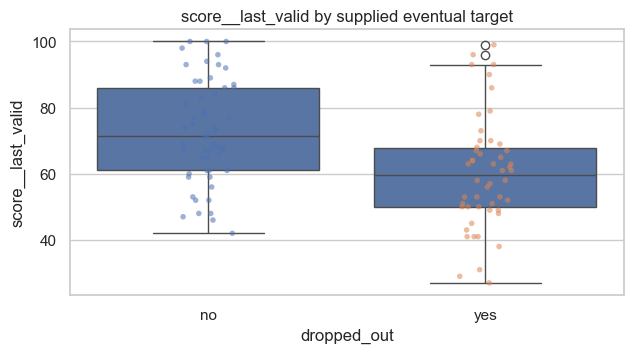

score__last_valid: target rate by quantile


dropped_out,no,yes
score__last_valid,,
"(26.999, 53.0]",0.276,0.724
"(53.0, 66.0]",0.417,0.583
"(66.0, 78.25]",0.680,0.320
"(78.25, 100.0]",0.731,0.269


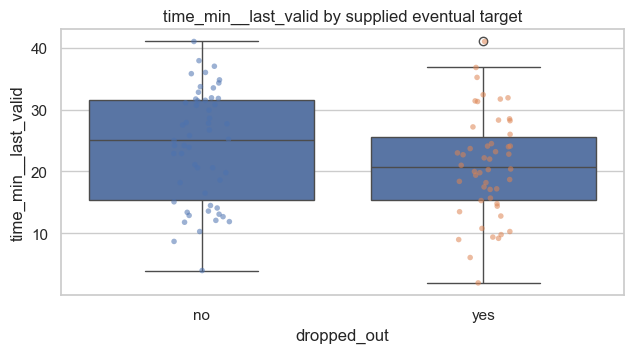

time_min__last_valid: target rate by quantile


dropped_out,no,yes
time_min__last_valid,,
"(1.999, 15.25]",0.538,0.462
"(15.25, 22.9]",0.333,0.667
"(22.9, 30.1]",0.520,0.480
"(30.1, 41.0]",0.692,0.308


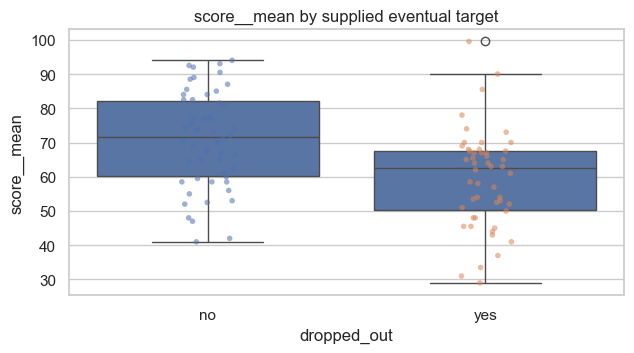

score__mean: target rate by quantile


dropped_out,no,yes
score__mean,,
"(28.999, 54.0]",0.259,0.741
"(54.0, 66.25]",0.480,0.520
"(66.25, 74.125]",0.500,0.500
"(74.125, 99.5]",0.846,0.154


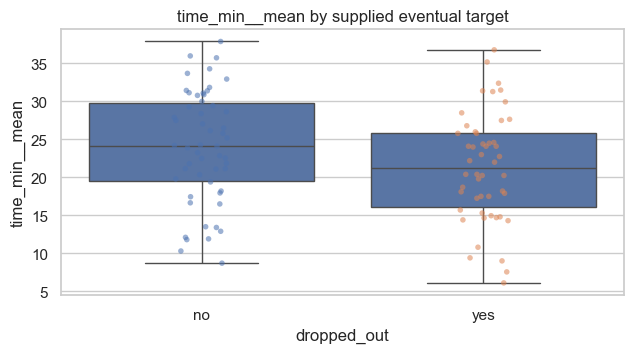

time_min__mean: target rate by quantile


dropped_out,no,yes
time_min__mean,,
"(6.098999999999999, 17.5]",0.407,0.593
"(17.5, 22.925]",0.520,0.480
"(22.925, 28.025]",0.462,0.538
"(28.025, 37.9]",0.692,0.308


In [6]:
def compare_feature(df, feature, target="dropped_out", bins=4):
    if feature not in df.columns:
        return
    d = df[[feature, target]].copy()
    d[feature] = pd.to_numeric(d[feature], errors="coerce")
    d = d.dropna(subset=[target])
    if d[feature].notna().sum() == 0 or d[feature].nunique(dropna=True) < 2:
        print(f"Skip {feature}: insufficient variation/valid values")
        return
    if d[feature].nunique(dropna=True) <= 8:
        print(f"\n{feature}: target share by category (including missing)")
        display(pd.crosstab(d[feature].round(3).astype("string").fillna("<MISSING>"), d[target], normalize="index").round(3))
    else:
        plt.figure(figsize=(6.5,3.7))
        sns.boxplot(data=d, x=target, y=feature)
        sns.stripplot(data=d, x=target, y=feature, hue=target, dodge=False, alpha=.55, size=4, legend=False)
        plt.title(f"{feature} by supplied eventual target")
        plt.tight_layout(); plt.show(); plt.close(); plt.close()
        try:
            b = pd.qcut(d[feature], q=min(bins, d[feature].nunique()), duplicates="drop")
            print(f"{feature}: target rate by quantile")
            display(pd.crosstab(b, d[target], normalize="index").round(3))
        except Exception:
            pass

for feat in ["score__last_valid","time_min__last_valid","score__mean","time_min__mean"]:
    compare_feature(group_b, feat)

## 5. Group C · 4+ total attempts: extensive global history features

The following table is the main global candidate feature matrix for 4+ students. Every statistic is calculated from the penultimate prefix only. The families deliberately include level, recency, weighted means, trends, fixed windows, volatility, time gaps, and observation-quality counts.

In [7]:
global_rows_c = []
for sid, p in prefixes.items():
    n_all = int(attempt_count_lookup.get(sid, 0))
    if n_all >= 4:
        global_rows_c.append({"student_id": sid, **make_global_features(p)})
global_c = pd.DataFrame(global_rows_c)
group_c = snap_meta[snap_meta["cohort"].eq("C: 4+ total attempts")].merge(global_c, on="student_id", how="left")
print("Group C rows:", len(group_c), "| candidate numeric features:", global_c.select_dtypes(include=np.number).shape[1])
display(global_c.describe().T.round(3))

Group C rows: 374 | candidate numeric features: 112


,count,mean,std,min,25%,50%,75%,max
feature_prefix_attempts_available,374.0,4.775,1.419,3.000,4.000,5.000,6.000,9.000
prefix_unique_modules,374.0,2.535,0.541,1.000,2.000,3.000,3.000,3.000
prefix_valid_score_n,374.0,4.770,1.414,3.000,4.000,5.000,6.000,9.000
prefix_invalid_999_n,374.0,0.005,0.073,0.000,0.000,0.000,0.000,1.000
prefix_invalid_score_frac,374.0,0.001,0.011,0.000,0.000,0.000,0.000,0.167
...,...,...,...,...,...,...,...,...
gap_hours__weighted_exp_gamma_0.9,374.0,210.938,121.354,12.763,125.207,181.943,266.253,668.453
history_span_hours,374.0,747.560,405.571,26.667,450.262,675.067,999.408,2029.217
time_total_valid_sum,374.0,113.314,42.155,27.900,83.450,110.500,142.300,231.500
time_total_valid_n,374.0,4.591,1.465,2.000,3.000,4.000,6.000,9.000


### 5.1 Target association: level, recency, and weighted summaries

For each feature, inspect the distributions by eventual target and quantile-bin target rates. These plots are exploratory and are not a feature-selection score; small samples and correlated features can create apparently strong separations.

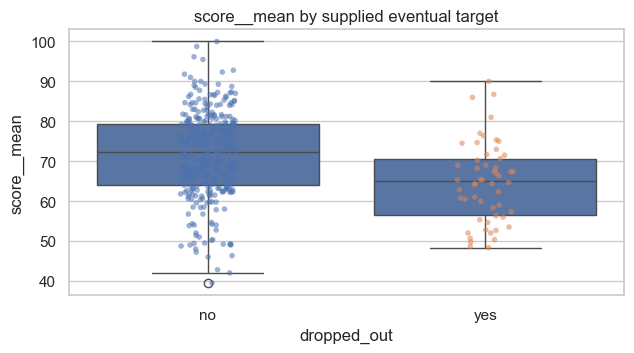

score__mean: target rate by quantile


dropped_out,no,yes
score__mean,,
"(39.499, 63.2]",0.758,0.242
"(63.2, 70.562]",0.815,0.185
"(70.562, 78.964]",0.892,0.108
"(78.964, 100.0]",0.957,0.043


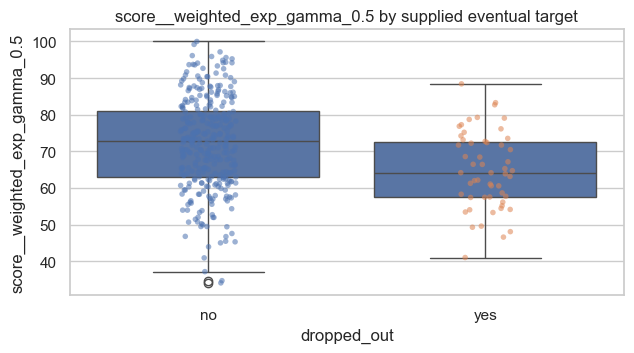

score__weighted_exp_gamma_0.5: target rate by quantile


dropped_out,no,yes
score__weighted_exp_gamma_0.5,,
"(34.066, 62.143]",0.747,0.253
"(62.143, 71.497]",0.870,0.130
"(71.497, 79.394]",0.839,0.161
"(79.394, 100.0]",0.968,0.032


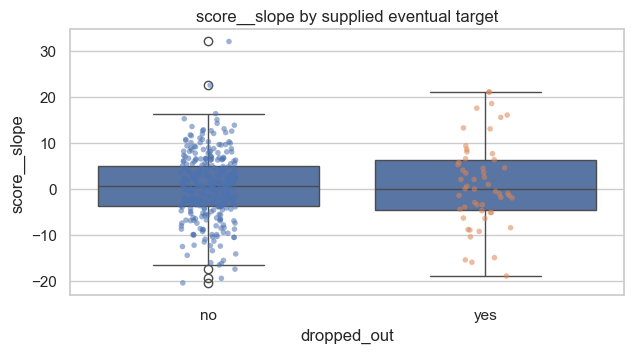

score__slope: target rate by quantile


dropped_out,no,yes
score__slope,,
"(-20.501, -3.8]",0.830,0.170
"(-3.8, 0.5]",0.871,0.129
"(0.5, 5.275]",0.882,0.118
"(5.275, 32.0]",0.840,0.160


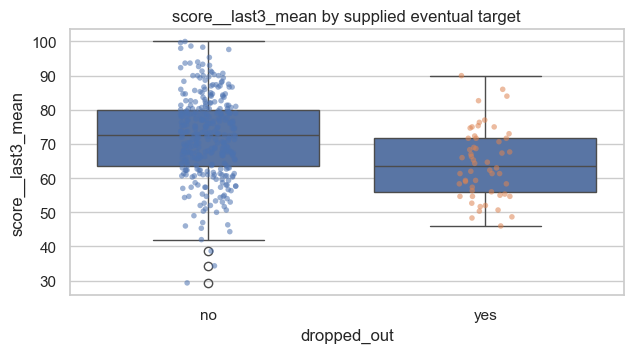

score__last3_mean: target rate by quantile


dropped_out,no,yes
score__last3_mean,,
"(29.331999999999997, 62.333]",0.732,0.268
"(62.333, 71.167]",0.856,0.144
"(71.167, 79.0]",0.884,0.116
"(79.0, 100.0]",0.957,0.043


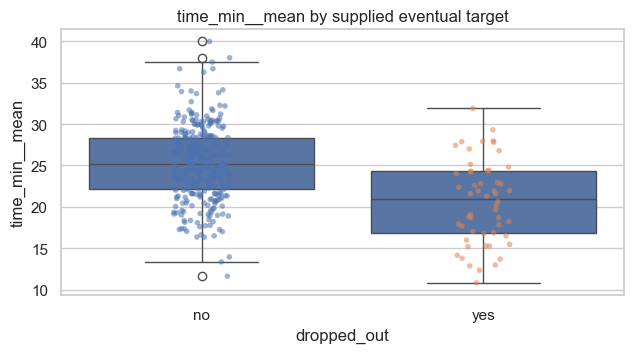

time_min__mean: target rate by quantile


dropped_out,no,yes
time_min__mean,,
"(10.824, 21.535]",0.702,0.298
"(21.535, 24.675]",0.839,0.161
"(24.675, 27.93]",0.914,0.086
"(27.93, 39.967]",0.968,0.032


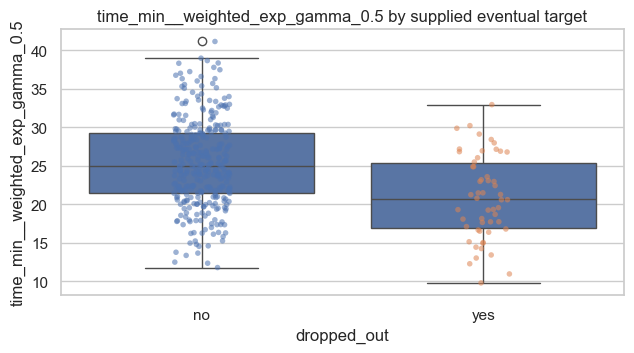

time_min__weighted_exp_gamma_0.5: target rate by quantile


dropped_out,no,yes
time_min__weighted_exp_gamma_0.5,,
"(9.799000000000001, 20.624]",0.713,0.287
"(20.624, 24.375]",0.882,0.118
"(24.375, 28.594]",0.871,0.129
"(28.594, 41.157]",0.957,0.043


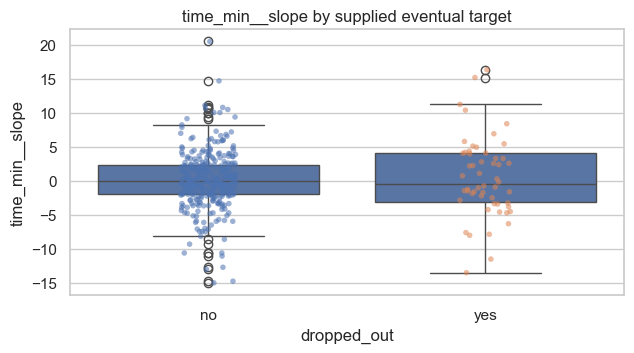

time_min__slope: target rate by quantile


dropped_out,no,yes
time_min__slope,,
"(-15.001, -2.058]",0.819,0.181
"(-2.058, -0.00571]",0.882,0.118
"(-0.00571, 2.547]",0.935,0.065
"(2.547, 20.5]",0.787,0.213


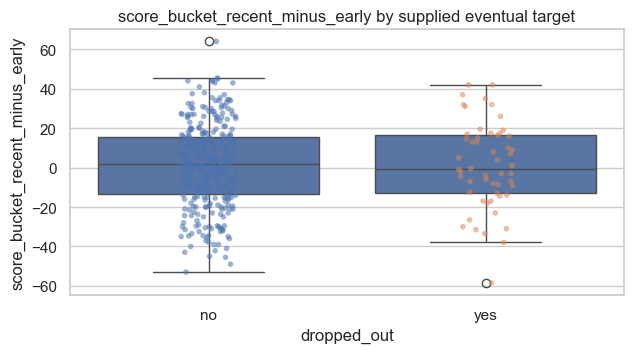

score_bucket_recent_minus_early: target rate by quantile


dropped_out,no,yes
score_bucket_recent_minus_early,,
"(-58.501, -13.5]",0.863,0.137
"(-13.5, 1.0]",0.828,0.172
"(1.0, 16.0]",0.883,0.117
"(16.0, 64.0]",0.848,0.152


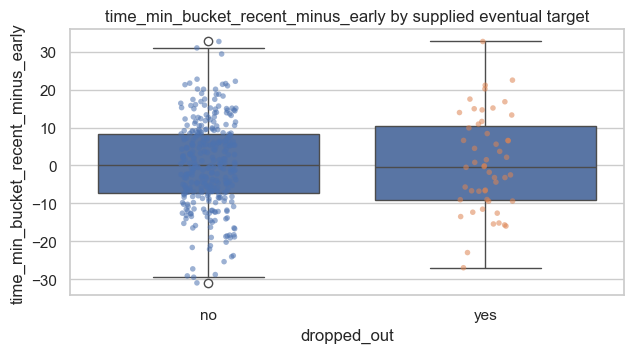

time_min_bucket_recent_minus_early: target rate by quantile


dropped_out,no,yes
time_min_bucket_recent_minus_early,,
"(-31.001, -7.254]",0.844,0.156
"(-7.254, 0.0167]",0.856,0.144
"(0.0167, 8.429]",0.889,0.111
"(8.429, 32.7]",0.844,0.156


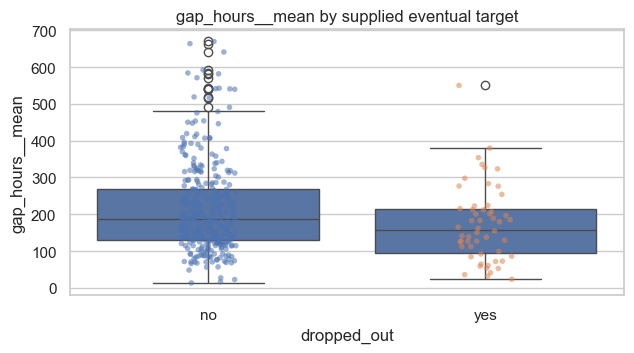

gap_hours__mean: target rate by quantile


dropped_out,no,yes
gap_hours__mean,,
"(13.332, 126.621]",0.798,0.202
"(126.621, 184.526]",0.860,0.140
"(184.526, 266.836]",0.871,0.129
"(266.836, 669.925]",0.894,0.106



prefix_unique_modules: target share by category (including missing)


dropped_out,no,yes
prefix_unique_modules,,
1,1.000,0.000
2,0.804,0.196
3,0.889,0.111



prefix_invalid_score_frac: target share by category (including missing)


dropped_out,no,yes
prefix_invalid_score_frac,,
0.0,0.855,0.145
0.143,1.000,0.000
0.167,1.000,0.000


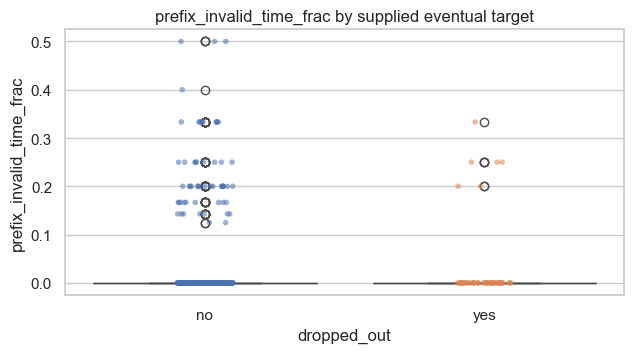

prefix_invalid_time_frac: target rate by quantile


dropped_out,no,yes
prefix_invalid_time_frac,,
"(-0.001, 0.5]",0.856,0.144


,feature,n_valid,mean_no,mean_yes,mean_yes_minus_no,target_corr,abs_target_corr
52,time_total_valid_sum,374,120.277,72.054,-48.223,-0.403,0.403
47,prefix_valid_score_n,374,4.969,3.593,-1.376,-0.342,0.342
19,time_min__mean,374,25.268,20.586,-4.682,-0.342,0.342
34,time_min__weighted_exp_gamma_0.9,374,25.269,20.636,-4.633,-0.339,0.339
25,time_min__last5_mean,374,25.278,20.578,-4.700,-0.335,0.335
...,...,...,...,...,...,...,...
17,score__first_to_last_change,374,0.766,1.852,1.086,0.016,0.016
61,time_min_bucket_recent_minus_early,360,0.289,0.666,0.377,0.011,0.011
8,score__last5_minus_earlier_mean,112,-1.028,-2.600,-1.572,-0.010,0.010
37,time_min__mean_abs_change,374,9.631,9.695,0.064,0.005,0.005


In [8]:
global_feature_candidates = [
    "score__mean","score__median","score__std","score__range","score__last_valid",
    "score__last3_mean","score__last5_mean","score__last3_minus_earlier_mean","score__last5_minus_earlier_mean",
    "score__weighted_linear_avg","score__weighted_quadratic_avg","score__weighted_cubic_avg",
    "score__weighted_exp_gamma_0.3","score__weighted_exp_gamma_0.5","score__weighted_exp_gamma_0.7","score__weighted_exp_gamma_0.9",
    "score__slope","score__first_to_last_change","score__mean_abs_change",
    "time_min__mean","time_min__median","time_min__std","time_min__range","time_min__last_valid",
    "time_min__last3_mean","time_min__last5_mean","time_min__last3_minus_earlier_mean","time_min__last5_minus_earlier_mean",
    "time_min__weighted_linear_avg","time_min__weighted_quadratic_avg","time_min__weighted_cubic_avg",
    "time_min__weighted_exp_gamma_0.3","time_min__weighted_exp_gamma_0.5","time_min__weighted_exp_gamma_0.7","time_min__weighted_exp_gamma_0.9",
    "time_min__slope","time_min__first_to_last_change","time_min__mean_abs_change",
    "gap_hours__mean","gap_hours__median","gap_hours__std","gap_hours__last3_mean","gap_hours__last5_mean",
    "gap_hours__weighted_exp_gamma_0.5","gap_hours__slope","history_span_hours",
    "prefix_unique_modules","prefix_valid_score_n","prefix_invalid_999_n","prefix_invalid_score_frac",
    "prefix_valid_time_n","prefix_invalid_time_frac","time_total_valid_sum","score_time_corr",
    "score_bucket_early_mean","score_bucket_middle_mean","score_bucket_recent_mean","score_bucket_recent_minus_early",
    "time_min_bucket_early_mean","time_min_bucket_middle_mean","time_min_bucket_recent_mean","time_min_bucket_recent_minus_early"
]
# Compact plots for representative feature families; the table below covers every candidate.
representative_features = [
    "score__mean", "score__weighted_exp_gamma_0.5", "score__slope",
    "score__last3_mean", "time_min__mean", "time_min__weighted_exp_gamma_0.5",
    "time_min__slope", "score_bucket_recent_minus_early", "time_min_bucket_recent_minus_early", "gap_hours__mean", "prefix_unique_modules",
    "prefix_invalid_score_frac", "prefix_invalid_time_frac"
]
for feat in representative_features:
    compare_feature(group_c, feat, bins=4)

# Rank all numeric candidate features by absolute point-biserial correlation with the supplied label.
# This is an exploratory descriptive ranking only; it is not used for selection or training.
target_binary = group_c["dropped_out"].map({"no": 0, "yes": 1})
assoc_rows = []
for feat in global_feature_candidates:
    if feat not in group_c:
        continue
    x = pd.to_numeric(group_c[feat], errors="coerce")
    ok = x.notna() & target_binary.notna()
    corr = x[ok].corr(target_binary[ok]) if ok.sum() >= 5 and x[ok].nunique() > 1 else np.nan
    mean_no = x[group_c["dropped_out"].eq("no")].mean()
    mean_yes = x[group_c["dropped_out"].eq("yes")].mean()
    assoc_rows.append({"feature": feat, "n_valid": int(ok.sum()), "mean_no": mean_no,
                       "mean_yes": mean_yes, "mean_yes_minus_no": mean_yes-mean_no,
                       "target_corr": corr, "abs_target_corr": abs(corr) if pd.notna(corr) else np.nan})
association_summary = pd.DataFrame(assoc_rows).sort_values("abs_target_corr", ascending=False)
display(association_summary.round(3))

## 6. Explicit slope / trajectory visualizations

A single slope can hide nonlinear patterns. These plots compare first-to-last changes and fit simple within-prefix linear trends. The line is descriptive only; no extrapolation beyond the observed prefix is performed.

The polynomial-weighted averages above are **recency-weighted means**, not polynomial regression. The additional polynomial trend features below fit degree-2 curves only when at least four valid points exist, and summarize the fitted curvature term. Avoid overinterpreting these with short histories.

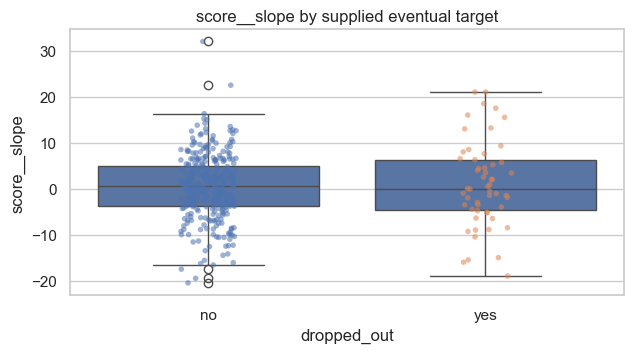

score__slope: target rate by quantile


dropped_out,no,yes
score__slope,,
"(-20.501, -3.8]",0.830,0.170
"(-3.8, 0.5]",0.871,0.129
"(0.5, 5.275]",0.882,0.118
"(5.275, 32.0]",0.840,0.160


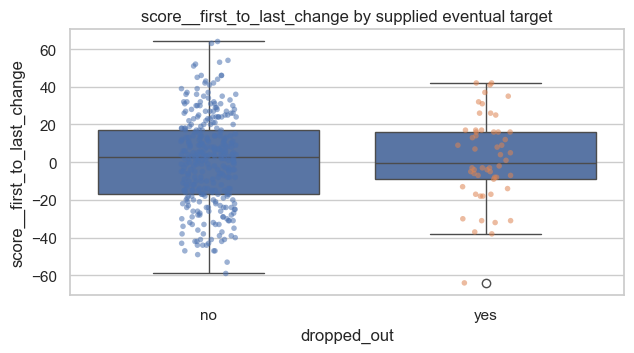

score__first_to_last_change: target rate by quantile


dropped_out,no,yes
score__first_to_last_change,,
"(-64.001, -15.75]",0.883,0.117
"(-15.75, 2.0]",0.819,0.181
"(2.0, 17.0]",0.835,0.165
"(17.0, 64.0]",0.888,0.112


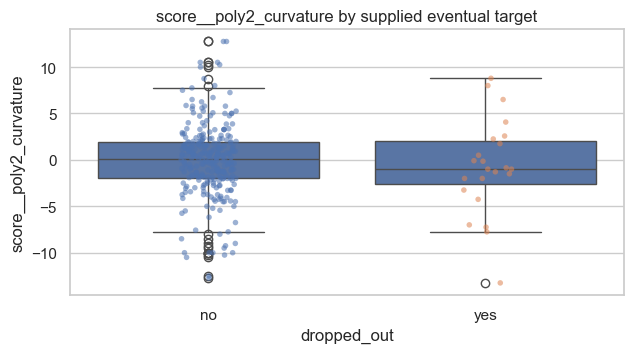

score__poly2_curvature: target rate by quantile


dropped_out,no,yes
score__poly2_curvature,,
"(-13.251, -2.0]",0.904,0.096
"(-2.0, 0.00893]",0.890,0.110
"(0.00893, 1.938]",0.973,0.027
"(1.938, 12.75]",0.918,0.082


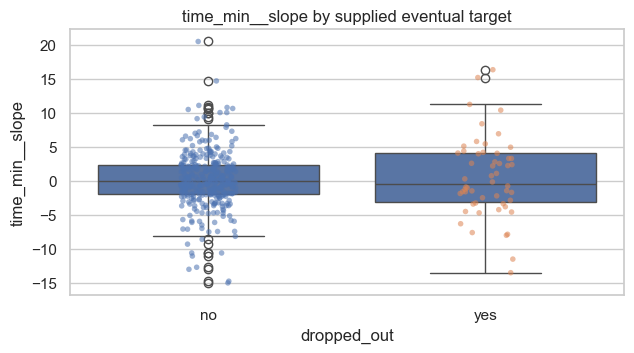

time_min__slope: target rate by quantile


dropped_out,no,yes
time_min__slope,,
"(-15.001, -2.058]",0.819,0.181
"(-2.058, -0.00571]",0.882,0.118
"(-0.00571, 2.547]",0.935,0.065
"(2.547, 20.5]",0.787,0.213


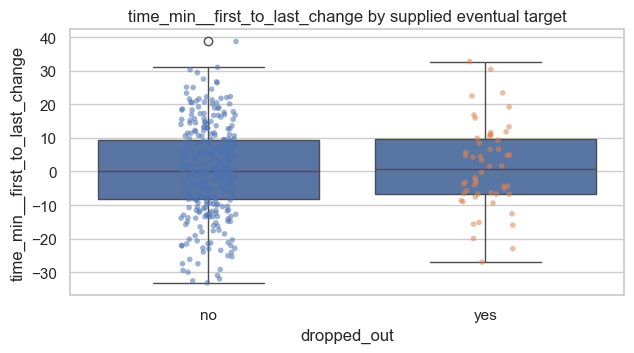

time_min__first_to_last_change: target rate by quantile


dropped_out,no,yes
time_min__first_to_last_change,,
"(-33.201, -7.85]",0.894,0.106
"(-7.85, 0.15]",0.817,0.183
"(0.15, 9.475]",0.860,0.140
"(9.475, 38.7]",0.851,0.149


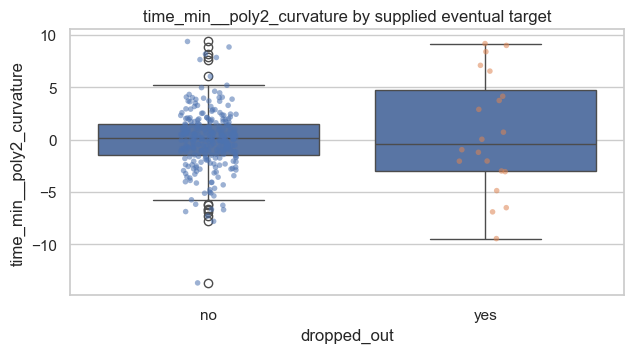

time_min__poly2_curvature: target rate by quantile


dropped_out,no,yes
time_min__poly2_curvature,,
"(-13.676, -1.612]",0.884,0.116
"(-1.612, 0.075]",0.957,0.043
"(0.075, 1.659]",0.986,0.014
"(1.659, 9.35]",0.884,0.116


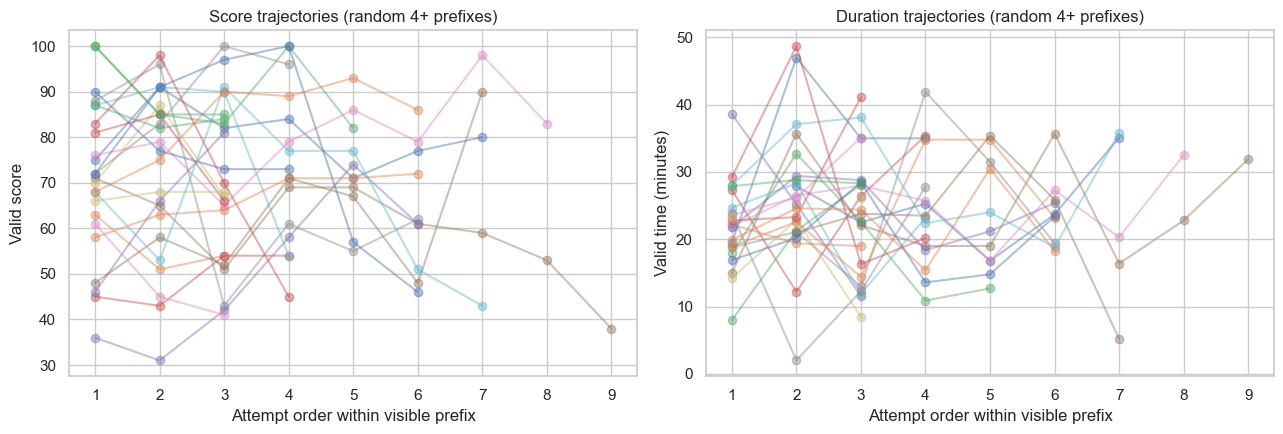

In [9]:
def trajectory_features(s, name):
    s = pd.to_numeric(pd.Series(s), errors="coerce").reset_index(drop=True)
    mask = s.notna().to_numpy()
    y = s.to_numpy(dtype=float)[mask]
    x = np.arange(len(s), dtype=float)[mask]
    out = {}
    if len(y) >= 4:
        coef = np.polyfit(x, y, deg=2)
        out[f"{name}__poly2_curvature"] = float(coef[0])
        out[f"{name}__poly2_linear_term"] = float(coef[1])
    else:
        out[f"{name}__poly2_curvature"] = np.nan
        out[f"{name}__poly2_linear_term"] = np.nan
    if len(y) >= 5:
        coef3 = np.polyfit(x, y, deg=3)
        out[f"{name}__poly3_cubic_term"] = float(coef3[0])
    else:
        out[f"{name}__poly3_cubic_term"] = np.nan
    return out

poly_rows=[]
for sid, p in prefixes.items():
    n_all = int(attempt_count_lookup.get(sid, 0))
    if n_all >= 4:
        row={"student_id":sid}
        row.update(trajectory_features(p["score_valid"],"score"))
        row.update(trajectory_features(p["time_valid_min"],"time_min"))
        poly_rows.append(row)
poly_features=pd.DataFrame(poly_rows)
group_c=group_c.merge(poly_features,on="student_id",how="left")

for feat in ["score__slope","score__first_to_last_change","score__poly2_curvature",
             "time_min__slope","time_min__first_to_last_change","time_min__poly2_curvature"]:
    compare_feature(group_c, feat)

# Plot trajectories for a small random sample, each line is a prefix only.
rng=np.random.default_rng(RANDOM_STATE)
eligible=[sid for sid,p in prefixes.items() if int(base.loc[base["student_id"].eq(sid),"eventual_attempt_count_cohort_only"].iloc[0])>=4]
sample_ids=rng.choice(eligible, size=min(24,len(eligible)), replace=False) if eligible else []
fig, axes=plt.subplots(1,2,figsize=(13,4.5))
for sid in sample_ids:
    p=prefixes[sid]
    target=outcomes.loc[outcomes["student_id"].eq(sid),"dropped_out"]
    label=str(target.iloc[0]) if len(target) else "unknown"
    axes[0].plot(np.arange(1,len(p)+1),p["score_valid"],marker="o",alpha=.45,label=label)
    axes[1].plot(np.arange(1,len(p)+1),p["time_valid_min"],marker="o",alpha=.45,label=label)
axes[0].set(title="Score trajectories (random 4+ prefixes)",xlabel="Attempt order within visible prefix",ylabel="Valid score")
axes[1].set(title="Duration trajectories (random 4+ prefixes)",xlabel="Attempt order within visible prefix",ylabel="Valid time (minutes)")
plt.tight_layout(); plt.show(); plt.close(); plt.close()

## 7. Fixed windows and alternative recency weighting

Compare last 3 and last 5 **attempt rows** (not last 3/5 valid values) so missingness is preserved and window definitions remain operationally clear. The per-window valid counts accompany every average. Weighted averages assign weights by the original attempt positions and then omit invalid values. Therefore, a missing recent value does not promote an older observation to the newest position; valid-count/missingness features should still accompany every weighted summary.

Additional robust alternatives worth considering later:
- Exponentially weighted mean with a tuned decay parameter (gamma).
- Median of last 3/5 rows, resistant to one extreme valid score/time.
- Recent-vs-earlier mean difference and ratio (ratio only when denominator is safely non-zero).
- Winsorized duration summaries if the duration distribution is heavily skewed (fit clipping thresholds on training data only).

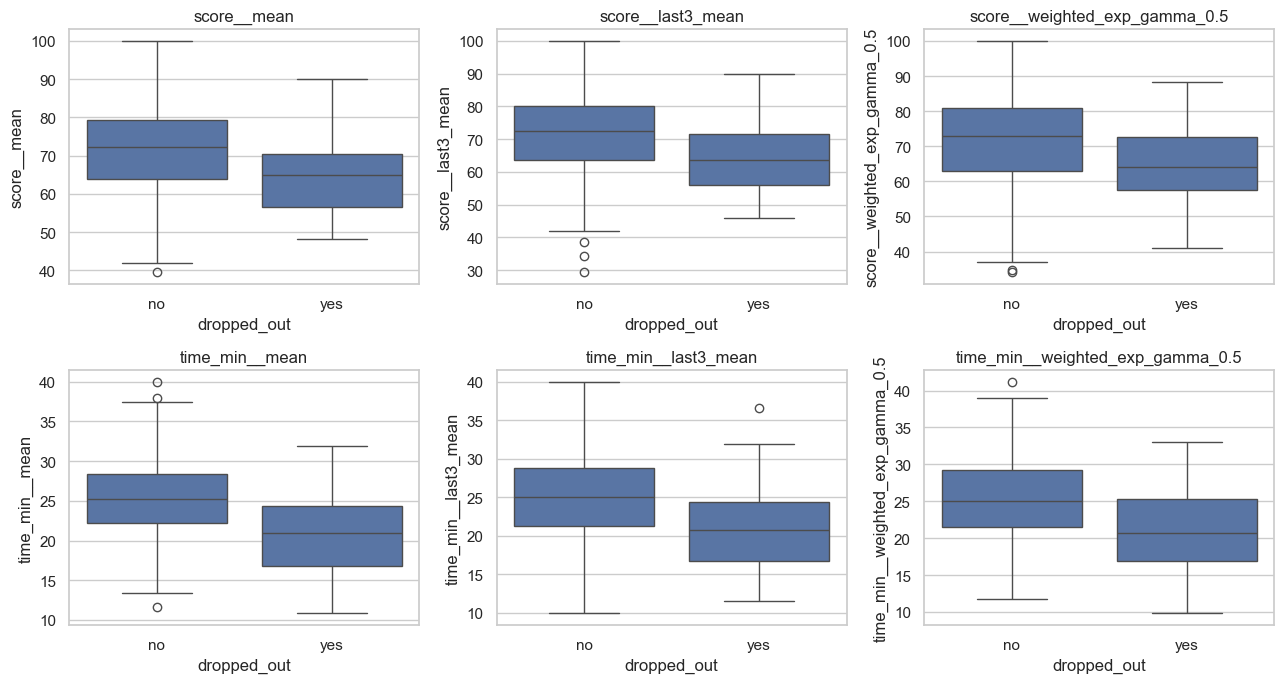

In [10]:
# Compare a compact subset of recency variants in a 2x2 panel for readability.
recency_feats=["score__mean","score__last3_mean","score__weighted_exp_gamma_0.5",
               "time_min__mean","time_min__last3_mean","time_min__weighted_exp_gamma_0.5"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feat in zip(axes.flat, recency_feats):
    if feat in group_c.columns:
        sns.boxplot(data=group_c, x="dropped_out", y=feat, ax=ax)
        ax.set_title(feat)
    else:
        ax.set_visible(False)
plt.tight_layout(); plt.show(); plt.close(); plt.close()


## 8. Module-specific feature factory

For every module present in the dataset, construct candidate features from the prefix only:
- Exposure: attempt count and share of prefix attempts.
- Score: valid count, missing fraction, mean/median/std/min/max, last valid score, first-to-last change, linear slope, last-3-within-module mean, and recency-weighted mean.
- Time: valid count, missing fraction, total valid minutes, mean/median/std, last valid time, first-to-last change, linear slope, last-3-within-module mean, and recency-weighted mean.
- Windowed exposure: module attempts in the last 3/5 **global attempt rows**.
- Improvement flags: score/time first-to-last change only when at least two valid module-specific observations exist; explicit `*_change_defined` flags show whether a comparison is possible.

Important distinction: a module not attempted in the visible prefix has `attempt_count=0` and `attempted=0`, but score/time aggregates remain NaN. A module attempted once can have a last score/time but cannot have a within-module first-to-last change or trend.

In [11]:
module_values=sorted(attempts["lesson_id"].dropna().astype(str).unique().tolist())

def fast_module_series_features(values, tag, windows=(3,)):
    s = pd.to_numeric(values, errors="coerce")
    arr = s.to_numpy(dtype=float)
    mask = np.isfinite(arr)
    valid = arr[mask]
    out = {
        f"{tag}__valid_n": int(mask.sum()),
        f"{tag}__missing_n": int((~mask).sum()),
        f"{tag}__missing_frac": float((~mask).mean()) if len(arr) else np.nan,
        f"{tag}__mean": float(valid.mean()) if len(valid) else np.nan,
        f"{tag}__median": float(np.median(valid)) if len(valid) else np.nan,
        f"{tag}__std": float(valid.std(ddof=0)) if len(valid) else np.nan,
        f"{tag}__min": float(valid.min()) if len(valid) else np.nan,
        f"{tag}__max": float(valid.max()) if len(valid) else np.nan,
        f"{tag}__range": float(valid.max()-valid.min()) if len(valid) else np.nan,
        f"{tag}__sum": float(valid.sum()) if len(valid) else np.nan,
        f"{tag}__last_valid": float(valid[-1]) if len(valid) else np.nan,
        f"{tag}__first_to_last_change": float(valid[-1]-valid[0]) if len(valid)>=2 else np.nan,
        f"{tag}__slope": float(np.polyfit(np.arange(len(arr),dtype=float)[mask],valid,1)[0]) if len(valid)>=2 else np.nan,
        f"{tag}__mean_abs_change": float(np.abs(np.diff(valid)).mean()) if len(valid)>=2 else np.nan,
    }
    for w in windows:
        win=arr[-w:]
        win=win[np.isfinite(win)]
        out[f"{tag}__last{w}_mean"]=float(win.mean()) if len(win) else np.nan
        out[f"{tag}__last{w}_std"]=float(win.std(ddof=0)) if len(win) else np.nan
        out[f"{tag}__last{w}_valid_n"]=int(len(win))
        out[f"{tag}__last{w}_minus_earlier_mean"]=np.nan
    # One module-level recency-weighted mean is enough for discovery without redundant computation.
    out[f"{tag}__weighted_exp_gamma_0.5"]=weighted_average(values,kind="exponential",gamma=0.5)
    return out

def module_feature_row(prefix):
    p=prefix.reset_index(drop=True).copy()
    out={"student_id":p["student_id"].iloc[0] if len(p) else None}
    last3=p.tail(3)
    last5=p.tail(5)
    for mod in module_values:
        m=p[p["lesson_id"].astype(str).eq(mod)].copy()
        tag=str(mod).replace(" ","_").replace("/","_")
        out[f"{tag}__attempt_count"]=int(len(m))
        out[f"{tag}__attempt_share"]=float(len(m)/len(p)) if len(p) else np.nan
        out[f"{tag}__attempted"]=int(len(m)>0)
        out[f"{tag}__last3_global_attempt_count"]=int(last3["lesson_id"].astype(str).eq(mod).sum())
        out[f"{tag}__last5_global_attempt_count"]=int(last5["lesson_id"].astype(str).eq(mod).sum())
        out.update(fast_module_series_features(m["score_valid"],f"{tag}__score",windows=(3,)))
        out.update(fast_module_series_features(m["time_valid_min"],f"{tag}__time_min",windows=(3,)))
        out[f"{tag}__score_change_defined"]=int(m["score_valid"].notna().sum()>=2)
        out[f"{tag}__time_change_defined"]=int(m["time_valid_min"].notna().sum()>=2)
        score_valid=m["score_valid"].dropna()
        time_valid=m["time_valid_min"].dropna()
        out[f"{tag}__score_improved"]=int(score_valid.iloc[-1]>score_valid.iloc[0]) if len(score_valid)>=2 else np.nan
        out[f"{tag}__time_increased"]=int(time_valid.iloc[-1]>time_valid.iloc[0]) if len(time_valid)>=2 else np.nan
        for w,win in [(3,last3),(5,last5)]:
            mw=win[win["lesson_id"].astype(str).eq(mod)]
            out[f"{tag}__score_last{w}_global_window_mean"]=safe_mean(mw["score_valid"])
            out[f"{tag}__time_last{w}_global_window_mean"]=safe_mean(mw["time_valid_min"])
            out[f"{tag}__score_last{w}_global_window_valid_n"]=int(mw["score_valid"].notna().sum())
            out[f"{tag}__time_last{w}_global_window_valid_n"]=int(mw["time_valid_min"].notna().sum())
    return out

module_rows=[]
for sid,p in prefixes.items():
    n_all=int(attempt_count_lookup.get(sid,0))
    if n_all>=4:
        module_rows.append(module_feature_row(p))
module_c=pd.DataFrame(module_rows)
module_c=module_c.merge(outcomes,on="student_id",how="left")
print("Module feature matrix shape:",module_c.shape)
display(module_c.iloc[:5,:min(24,module_c.shape[1])])

Module feature matrix shape: (374, 167)


,student_id,L1__attempt_count,L1__attempt_share,L1__attempted,L1__last3_global_attempt_count,L1__last5_global_attempt_count,L1__score__valid_n,L1__score__missing_n,L1__score__missing_frac,L1__score__mean,L1__score__median,L1__score__std,L1__score__min,L1__score__max,L1__score__range,L1__score__sum,L1__score__last_valid,L1__score__first_to_last_change,L1__score__slope,L1__score__mean_abs_change,L1__score__last3_mean,L1__score__last3_std,L1__score__last3_valid_n,L1__score__last3_minus_earlier_mean
0,S002,2,0.333333,1,0,1,2,0,0.0,68.0,68.0,9.0,59.0,77.0,18.0,136.0,59.0,-18.0,-18.0,18.0,68.0,9.0,2,NaN
1,S003,1,0.200000,1,0,1,1,0,0.0,66.0,66.0,0.0,66.0,66.0,0.0,66.0,66.0,NaN,NaN,NaN,66.0,0.0,1,NaN
2,S005,2,0.333333,1,0,1,2,0,0.0,98.5,98.5,1.5,97.0,100.0,3.0,197.0,100.0,3.0,3.0,3.0,98.5,1.5,2,NaN
3,S006,1,0.250000,1,0,1,1,0,0.0,79.0,79.0,0.0,79.0,79.0,0.0,79.0,79.0,NaN,NaN,NaN,79.0,0.0,1,NaN
4,S007,2,0.285714,1,0,0,2,0,0.0,54.0,54.0,2.0,52.0,56.0,4.0,108.0,52.0,-4.0,-4.0,4.0,54.0,2.0,2,NaN


## 9. Module feature visualizations and target association

The next cells focus on interpretability rather than selecting a single winning feature. They show:
1. Mean valid score and mean valid time by module and target.
2. Module exposure and valid-observation coverage.
3. Score/time differences by target.
4. Heatmaps of module means and module-wise differences between target groups.
5. Best-vs-worst observed module scores, score spread across modules, and time allocation differences.

These are prefix-only module summaries. A blank module cell means there is no valid observation, not a zero score/time.

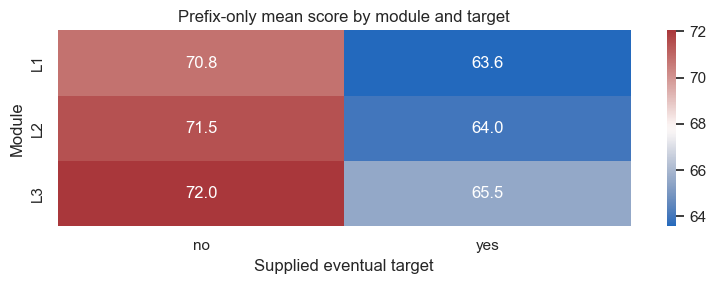

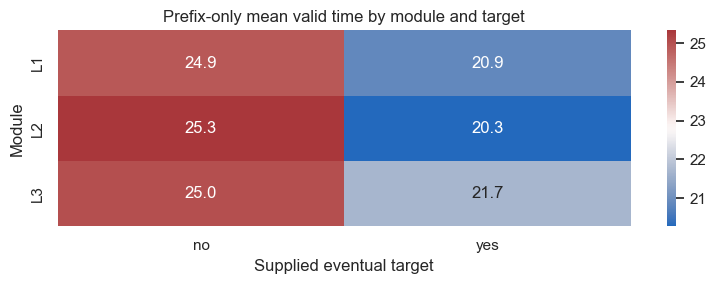

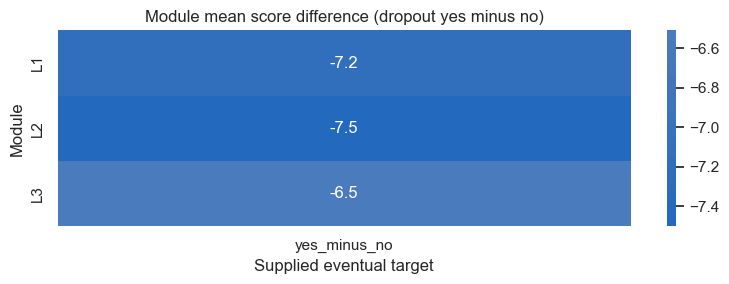

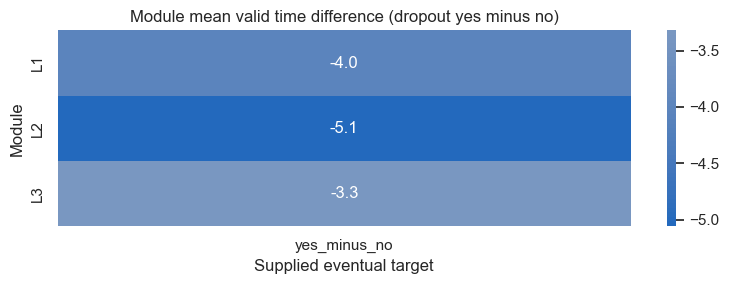

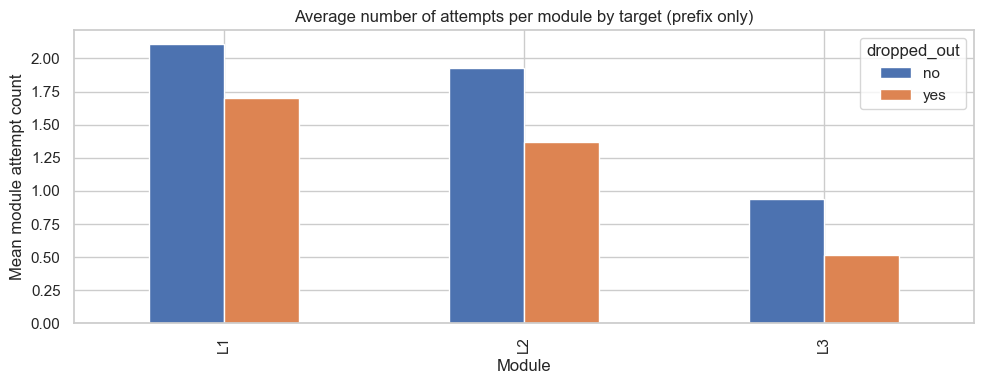

In [12]:
module_score_mean_cols=[f"{m}__score__mean" for m in module_values if f"{m}__score__mean" in module_c.columns]
module_time_mean_cols=[f"{m}__time_min__mean" for m in module_values if f"{m}__time_min__mean" in module_c.columns]
module_count_cols=[f"{m}__attempt_count" for m in module_values if f"{m}__attempt_count" in module_c.columns]

def module_target_heatmap(cols, title, difference=False, fmt=".1f"):
    if not cols: 
        print("No columns for",title); return
    mat=module_c.groupby("dropped_out")[cols].mean(numeric_only=True).T
    mat.index=[x.split("__")[0] for x in mat.index]
    if difference and mat.shape[1]>=2:
        mat=pd.DataFrame({"yes_minus_no":mat.get("yes",pd.Series(dtype=float))-mat.get("no",pd.Series(dtype=float))})
    plt.figure(figsize=(8,max(3,.55*len(mat))))
    sns.heatmap(mat,annot=True,fmt=fmt,cmap="vlag",center=0 if difference else None)
    plt.title(title); plt.xlabel("Supplied eventual target"); plt.ylabel("Module")
    plt.tight_layout(); plt.show(); plt.close(); plt.close()

module_target_heatmap(module_score_mean_cols,"Prefix-only mean score by module and target")
module_target_heatmap(module_time_mean_cols,"Prefix-only mean valid time by module and target")
module_target_heatmap(module_score_mean_cols,"Module mean score difference (dropout yes minus no)",difference=True)
module_target_heatmap(module_time_mean_cols,"Module mean valid time difference (dropout yes minus no)",difference=True)

# Exposure counts by target, stacked summary.
if module_count_cols:
    exposure=module_c.groupby("dropped_out")[module_count_cols].mean().T
    exposure.index=[x.split("__")[0] for x in exposure.index]
    exposure.plot(kind="bar",figsize=(10,4))
    plt.title("Average number of attempts per module by target (prefix only)")
    plt.ylabel("Mean module attempt count"); plt.xlabel("Module")
    plt.tight_layout(); plt.show(); plt.close(); plt.close()

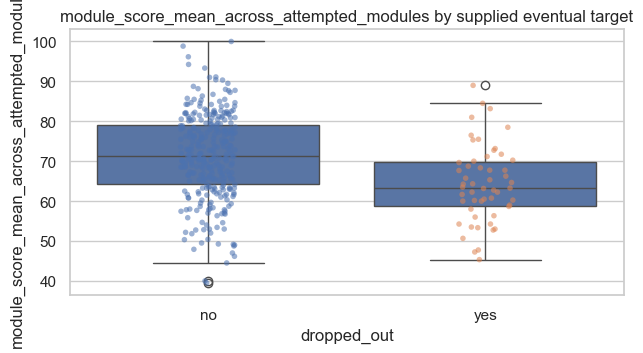

module_score_mean_across_attempted_modules: target rate by quantile


dropped_out,no,yes
module_score_mean_across_attempted_modules,,
"(39.499, 63.014]",0.728,0.272
"(63.014, 70.444]",0.815,0.185
"(70.444, 78.229]",0.922,0.078
"(78.229, 100.0]",0.946,0.054


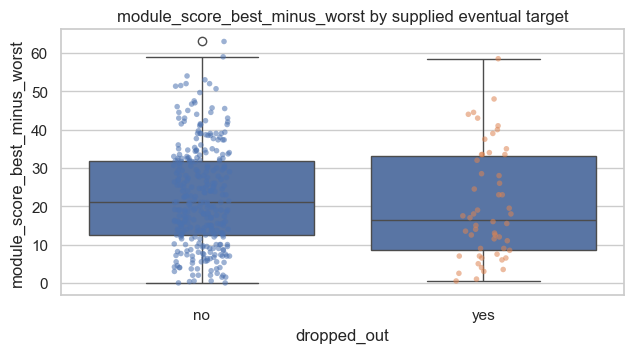

module_score_best_minus_worst: target rate by quantile


dropped_out,no,yes
module_score_best_minus_worst,,
"(-0.001, 12.0]",0.798,0.202
"(12.0, 19.667]",0.844,0.156
"(19.667, 31.958]",0.933,0.067
"(31.958, 63.0]",0.837,0.163


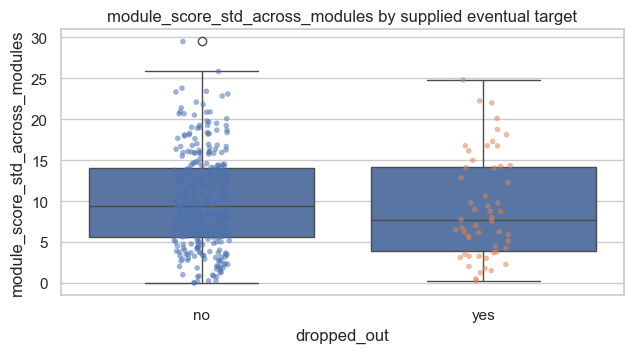

module_score_std_across_modules: target rate by quantile


dropped_out,no,yes
module_score_std_across_modules,,
"(-0.001, 5.523]",0.804,0.196
"(5.523, 8.973]",0.857,0.143
"(8.973, 14.088]",0.912,0.088
"(14.088, 29.5]",0.837,0.163



module_valid_score_modules_n: target share by category (including missing)


dropped_out,no,yes
module_valid_score_modules_n,,
2.0,0.804,0.196
3.0,0.889,0.111
<MISSING>,1.000,0.000


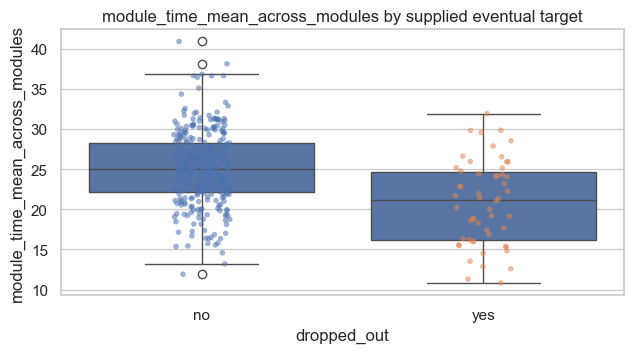

module_time_mean_across_modules: target rate by quantile


dropped_out,no,yes
module_time_mean_across_modules,,
"(10.824, 21.429]",0.692,0.308
"(21.429, 24.65]",0.868,0.132
"(24.65, 27.808]",0.911,0.089
"(27.808, 40.875]",0.934,0.066


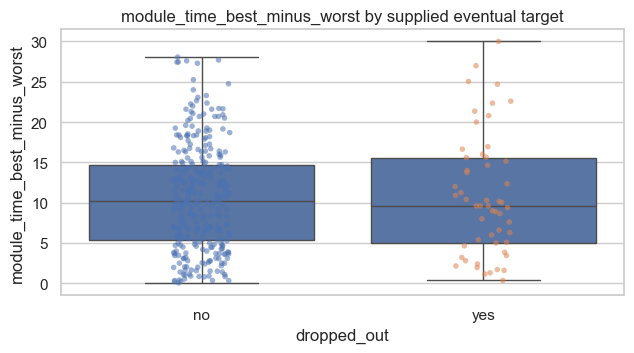

module_time_best_minus_worst: target rate by quantile


dropped_out,no,yes
module_time_best_minus_worst,,
"(0.049, 5.258]",0.835,0.165
"(5.258, 10.117]",0.846,0.154
"(10.117, 14.858]",0.889,0.111
"(14.858, 30.0]",0.835,0.165


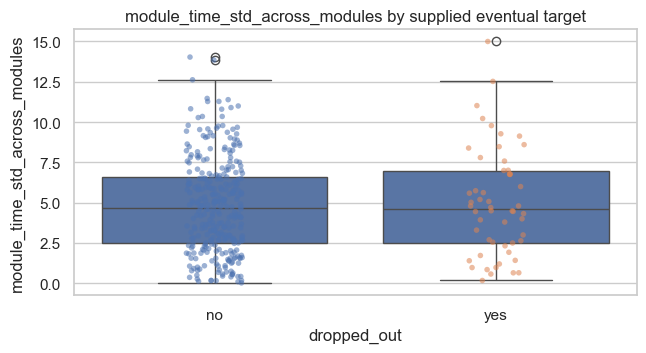

module_time_std_across_modules: target rate by quantile


dropped_out,no,yes
module_time_std_across_modules,,
"(0.024, 2.502]",0.846,0.154
"(2.502, 4.683]",0.857,0.143
"(4.683, 6.737]",0.889,0.111
"(6.737, 15.0]",0.813,0.187



module_valid_time_modules_n: target share by category (including missing)


dropped_out,no,yes
module_valid_time_modules_n,,
2.0,0.805,0.195
3.0,0.892,0.108
<MISSING>,1.000,0.000


In [13]:
# Cross-module contrast features. Require at least two valid module means to calculate spread.
if module_score_mean_cols:
    score_mat=module_c[module_score_mean_cols]
    module_c["module_score_mean_across_attempted_modules"]=score_mat.mean(axis=1,skipna=True)
    module_c["module_score_best_minus_worst"]=score_mat.max(axis=1,skipna=True)-score_mat.min(axis=1,skipna=True)
    module_c["module_score_std_across_modules"]=score_mat.std(axis=1,ddof=0,skipna=True)
    module_c["module_valid_score_modules_n"]=score_mat.notna().sum(axis=1)
    for c in ["module_score_best_minus_worst","module_score_std_across_modules","module_score_mean_across_attempted_modules","module_valid_score_modules_n"]:
        module_c.loc[module_c["module_valid_score_modules_n"]<2,c]=np.nan

if module_time_mean_cols:
    time_mat=module_c[module_time_mean_cols]
    module_c["module_time_mean_across_modules"]=time_mat.mean(axis=1,skipna=True)
    module_c["module_time_best_minus_worst"]=time_mat.max(axis=1,skipna=True)-time_mat.min(axis=1,skipna=True)
    module_c["module_time_std_across_modules"]=time_mat.std(axis=1,ddof=0,skipna=True)
    module_c["module_valid_time_modules_n"]=time_mat.notna().sum(axis=1)
    for c in ["module_time_best_minus_worst","module_time_std_across_modules","module_time_mean_across_modules","module_valid_time_modules_n"]:
        module_c.loc[module_c["module_valid_time_modules_n"]<2,c]=np.nan

for feat in ["module_score_mean_across_attempted_modules","module_score_best_minus_worst",
             "module_score_std_across_modules","module_valid_score_modules_n",
             "module_time_mean_across_modules","module_time_best_minus_worst",
             "module_time_std_across_modules","module_valid_time_modules_n"]:
    compare_feature(module_c,feat)

## 10. Module trajectories: first vs last valid observation, slope, and recent windows

This section explicitly handles sparse modules. First-to-last differences and slopes are undefined when fewer than two valid values exist. The `change_defined` flags and valid counts should travel with these features in any later model.

The “last 3 within module” window means the last three attempts **for that module**. The “last 3 global window” means attempts of that module among the last three overall attempt rows. These are different signals and both are provided.

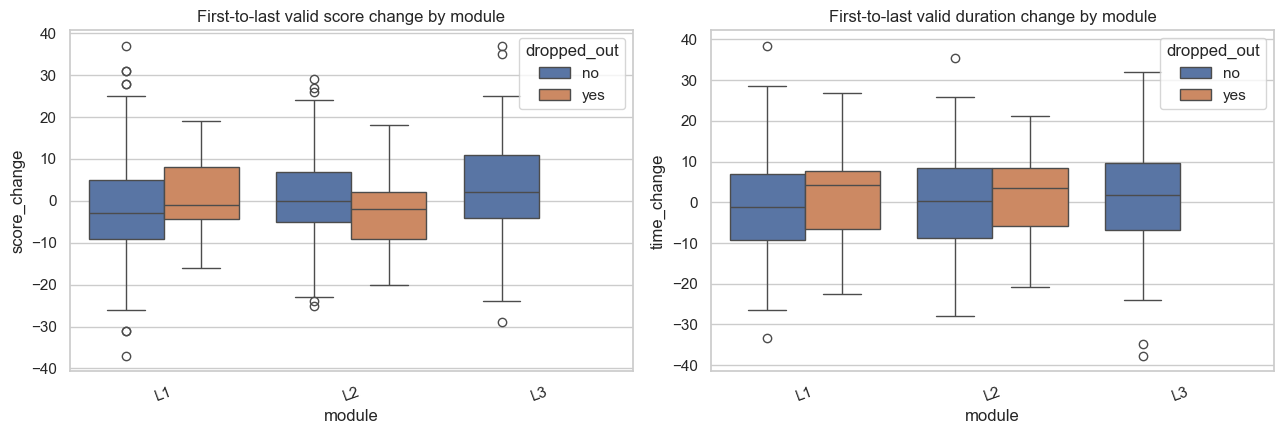

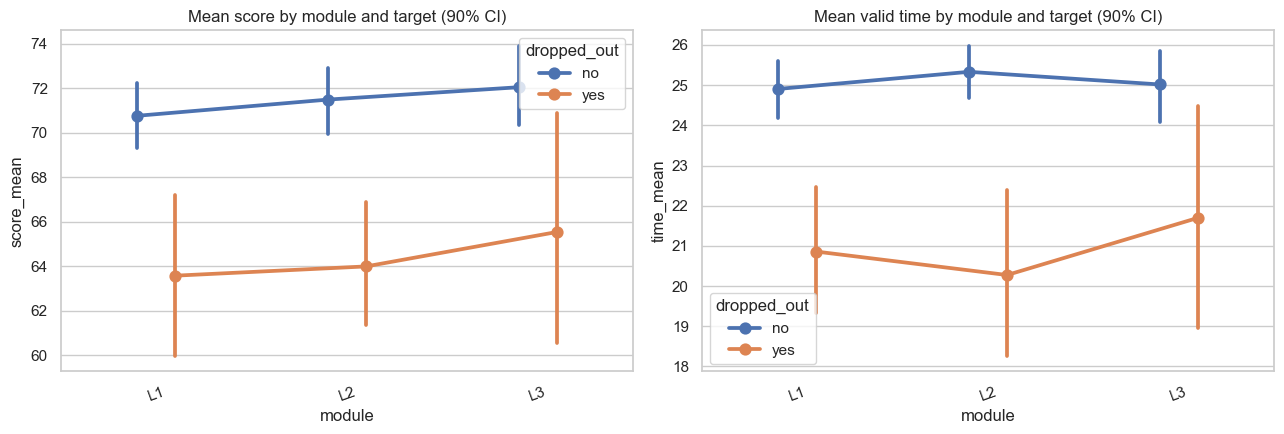

In [14]:
# Long-form module-level student summaries for plots; every row is derived from a student's prefix.
long_module=[]
for _,r in module_c.iterrows():
    for mod in module_values:
        tag=str(mod).replace(" ","_").replace("/","_")
        long_module.append({
            "student_id":r["student_id"],"dropped_out":r["dropped_out"],"module":mod,
            "attempt_count":r.get(f"{tag}__attempt_count",np.nan),
            "score_mean":r.get(f"{tag}__score__mean",np.nan),
            "score_change":r.get(f"{tag}__score__first_to_last_change",np.nan),
            "score_slope":r.get(f"{tag}__score__slope",np.nan),
            "score_last3_within_module":r.get(f"{tag}__score__last3_mean",np.nan),
            "time_total":r.get(f"{tag}__time_min__sum",np.nan),
            "time_mean":r.get(f"{tag}__time_min__mean",np.nan),
            "time_change":r.get(f"{tag}__time_min__first_to_last_change",np.nan),
            "time_slope":r.get(f"{tag}__time_min__slope",np.nan),
            "time_last3_within_module":r.get(f"{tag}__time_min__last3_mean",np.nan),
        })
long_module=pd.DataFrame(long_module)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.boxplot(data=long_module[long_module["attempt_count"]>0],x="module",y="score_change",hue="dropped_out",ax=axes[0])
sns.boxplot(data=long_module[long_module["attempt_count"]>0],x="module",y="time_change",hue="dropped_out",ax=axes[1])
axes[0].set_title("First-to-last valid score change by module")
axes[1].set_title("First-to-last valid duration change by module")
axes[0].tick_params(axis="x",rotation=20); axes[1].tick_params(axis="x",rotation=20)
plt.tight_layout(); plt.show(); plt.close(); plt.close()

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.pointplot(data=long_module[long_module["attempt_count"]>0],x="module",y="score_mean",hue="dropped_out",errorbar=("ci",90),dodge=.2,ax=axes[0])
sns.pointplot(data=long_module[long_module["attempt_count"]>0],x="module",y="time_mean",hue="dropped_out",errorbar=("ci",90),dodge=.2,ax=axes[1])
axes[0].set_title("Mean score by module and target (90% CI)")
axes[1].set_title("Mean valid time by module and target (90% CI)")
axes[0].tick_params(axis="x",rotation=20); axes[1].tick_params(axis="x",rotation=20)
plt.tight_layout(); plt.show(); plt.close(); plt.close()

## 11. Pairplot: selected global and module features

A pairplot can reveal nonlinear relationships, clusters, and redundancy across candidate features. To keep the plot readable and avoid a huge figure, we select a small set of complementary features and limit to columns with enough valid values. The hue is the supplied eventual target.

Pairplot is purely exploratory. It can be misleading under class imbalance and overlapping distributions; inspect counts and missingness before inferring separation.

Pairplot features: ['score__mean', 'score__weighted_exp_gamma_0.5', 'score__slope', 'score__std', 'time_min__mean', 'time_min__weighted_exp_gamma_0.5']


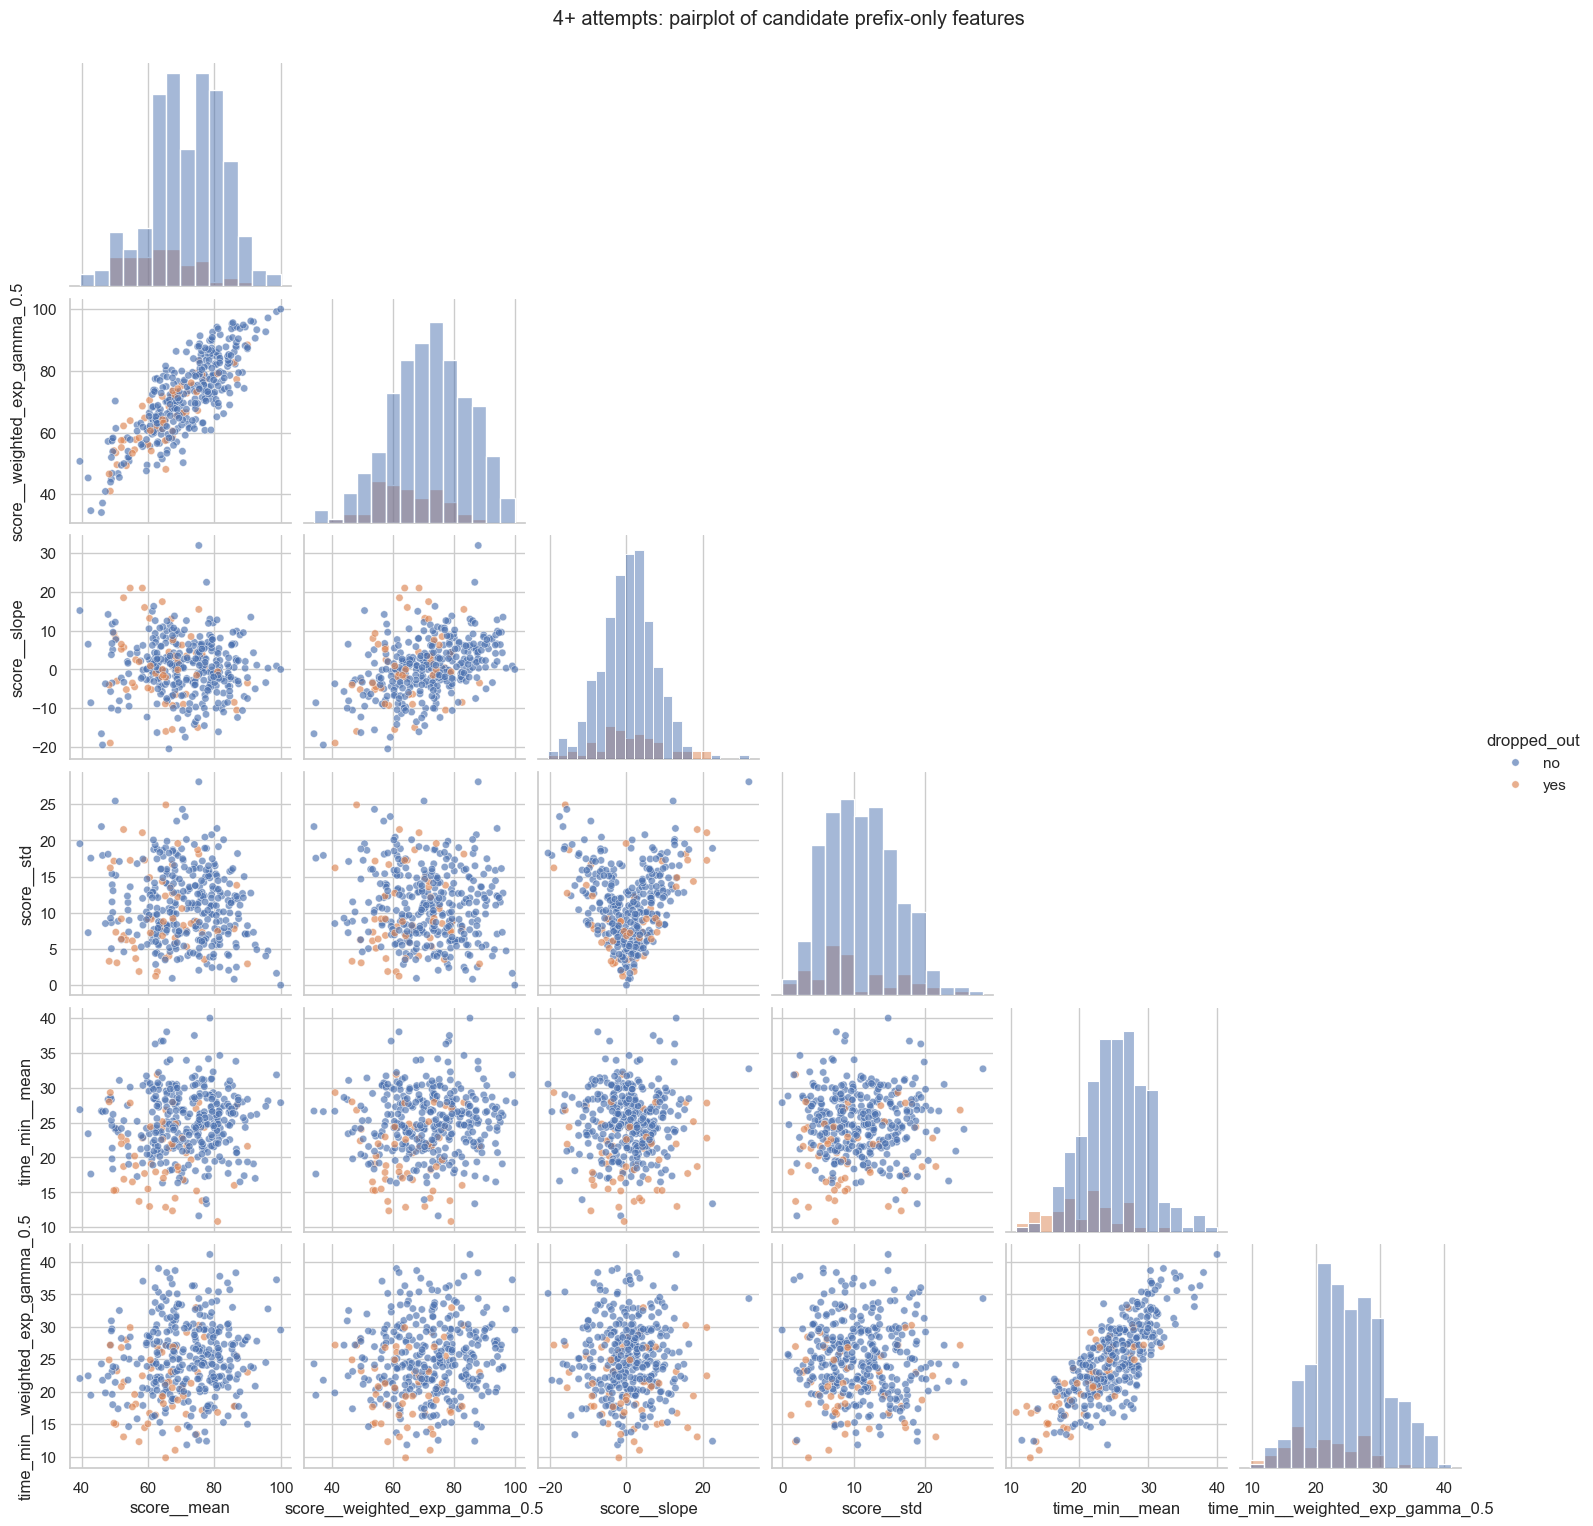

In [15]:
pair_candidates=[
    "score__mean","score__weighted_exp_gamma_0.5","score__slope","score__std",
    "time_min__mean","time_min__weighted_exp_gamma_0.5","time_min__slope",
    "gap_hours__mean","prefix_unique_modules",
    "module_score_best_minus_worst","module_score_std_across_modules",
    "module_time_mean_across_modules","module_time_std_across_modules",
]
pair_df=group_c.merge(
    module_c[["student_id"]+[c for c in ["module_score_best_minus_worst","module_score_std_across_modules",
                                         "module_time_mean_across_modules","module_time_std_across_modules"] if c in module_c]],
    on="student_id",how="left",suffixes=("","_module")
)
pair_cols=[]
for c in pair_candidates:
    if c in pair_df.columns and pd.to_numeric(pair_df[c],errors="coerce").notna().sum()>=max(8,int(.25*len(pair_df))) and pair_df[c].nunique(dropna=True)>1:
        pair_cols.append(c)
# Avoid duplicate columns after merge and keep a maximum of 8 variables for legibility.
pair_cols=list(dict.fromkeys(pair_cols))[:6]
print("Pairplot features:",pair_cols)
if len(pair_cols)>=2 and "dropped_out" in pair_df:
    pp=pair_df[pair_cols+["dropped_out"]].copy()
    for c in pair_cols:
        pp[c]=pd.to_numeric(pp[c],errors="coerce")
    pp=pp.dropna(subset=["dropped_out"])
    # seaborn pairplot uses pairwise-complete points per panel; missing values are retained until plotting.
    g=sns.pairplot(pp,vars=pair_cols,hue="dropped_out",corner=True,diag_kind="hist",
                   plot_kws={"alpha":.65,"s":28},diag_kws={"common_norm":False})
    g.fig.suptitle("4+ attempts: pairplot of candidate prefix-only features",y=1.02)
    plt.show(); plt.close('all')
else:
    print("Pairplot skipped: fewer than two usable features.")

## 12. Missingness is a feature family, not just a cleaning nuisance

Compare the proportion of missing/invalid score and duration observations by target, plus per-module valid coverage. Missingness may reflect logging problems, different attempt types, or engagement patterns; do not assume it is causal. Preserve both numerator counts and denominators.

,score_missing_frac,time_missing_frac,score_999_count,attempt_count_prefix,unique_modules_prefix
dropped_out,,,,,
no,0.001,0.043,0.006,4.975,2.553
yes,0.000,0.027,0.000,3.593,2.426


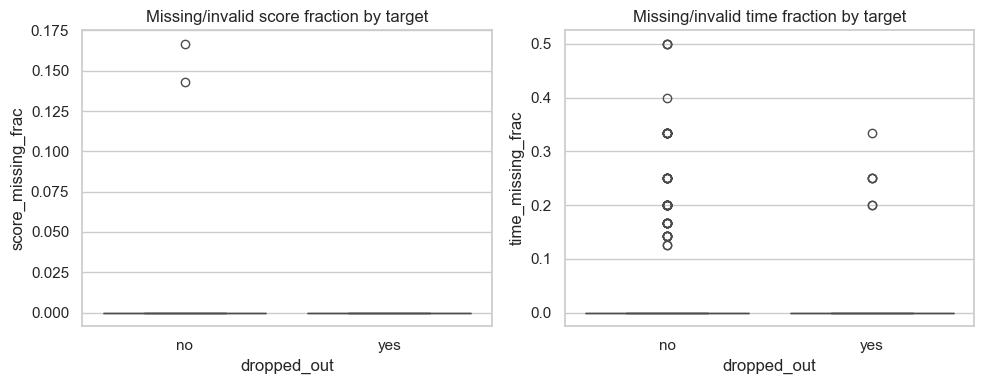

In [16]:
missing_summary=[]
for _,r in group_c.iterrows():
    p=prefixes[r["student_id"]]
    missing_summary.append({
        "student_id":r["student_id"],"dropped_out":r["dropped_out"],
        "score_missing_frac":p["score_valid"].isna().mean(),
        "time_missing_frac":p["time_valid_min"].isna().mean(),
        "score_999_count":p["score_is_999"].sum(),
        "attempt_count_prefix":len(p),
        "unique_modules_prefix":p["lesson_id"].nunique(dropna=True),
    })
missing_summary=pd.DataFrame(missing_summary)
display(missing_summary.groupby("dropped_out").mean(numeric_only=True).round(3))
fig,axes=plt.subplots(1,2,figsize=(10,4))
sns.boxplot(data=missing_summary,x="dropped_out",y="score_missing_frac",ax=axes[0])
sns.boxplot(data=missing_summary,x="dropped_out",y="time_missing_frac",ax=axes[1])
axes[0].set_title("Missing/invalid score fraction by target")
axes[1].set_title("Missing/invalid time fraction by target")
plt.tight_layout(); plt.show(); plt.close(); plt.close()

## 13. Candidate feature catalogue and leakage audit

This catalogue is a design inventory, not a final feature selection. All features should be re-generated inside each train/validation/test split when preprocessing parameters are learned (for example, imputation values, scaling, outlier clipping, or target encoding).

| Family | Examples | Eligibility / guardrail |
|---|---|---|
| Overall score level | mean, median, min/max, last valid | Valid scores only; 999 excluded |
| Score trend | linear slope, first-to-last change, polynomial curvature | At least 2 valid points; quadratic needs 4, cubic needs 5 |
| Recency | last 3/5 means, recent-minus-earlier | Last windows refer to prefix rows; track valid count |
| Weighted averages | linear/quadratic/cubic recency weights, exponential gamma 0.3/0.5/0.7/0.9 | Weight only available prefix observations; tune gamma on training data |
| Time | total valid minutes, mean/median, last-window mean, slope | Missing/negative durations excluded; include coverage counts |
| Attempt intervals | gap means, trends, history span | Timestamped prefix only; units are hours |
| Module profile | attempt count/share, score/time aggregates, module-specific slope | No attempt is not zero score/time |
| Module improvement | first-to-last valid score/time difference and flags | Undefined with fewer than 2 valid values |
| Cross-module differences | best-minus-worst, across-module standard deviation | Require at least 2 modules with valid values |
| Missingness | invalid score count, score/time missing fractions, per-module valid count | Missingness can reflect data capture, not just student behavior |
| Explanation text | counts, sentiment/quality/embedding | **Not eligible** without event timestamp proving text existed by prediction time |
| Profile fields | age group, country, device | Audit availability, fairness, and generalization |
| Refund request | `refund_requested` | Potentially downstream of disengagement; include only if known before prediction time |

### Leakage audit

- [x] Feature functions receive only the prefix through the penultimate attempt.
- [x] `score == 999` is excluded from valid score statistics.
- [x] Invalid/missing durations are excluded from time aggregates, not converted to zero.
- [x] Attempt count used for cohort selection is not in feature matrices.
- [x] Target label is attached after features and used only for comparisons.
- [x] No features use final attempt score, final attempt time, next-attempt gap, or future module exposure.
- [ ] Before modeling, decide how rows with missing timestamps are handled and audit tied timestamps/duplicate attempts.
- [ ] Ensure imputation, clipping, encoding, scaling, and feature selection are fit only on training folds.
- [ ] Split at student level and keep all rows for a student in one split.
- [ ] Verify the live system can determine which feature group to use without consulting future attempt counts.

## 14. Final takeaways and next steps

1. Start with a compact, interpretable baseline: current/prefix mean, recent mean, slope, valid counts, and missingness.
2. For 4+ histories, compare global recency-weighted means against fixed-window means and slopes; avoid keeping every highly correlated variant without validation.
3. Keep module-specific exposure separate from performance. A module with one valid score supports a level estimate but not an improvement estimate.
4. For duration features, always carry valid-duration count and missing fraction; sum of observed durations is not total true time if durations are missing.
5. Treat the many feature/target plots as hypothesis generation. Use grouped cross-validation or a held-out student split to assess generalization after feature definitions are frozen.
6. No training dataset is exported and no model is fit by this notebook.